In [ ]:
#Lab 2: Supervised Learning

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.metrics import (
  mean_absolute_error,
  mean_squared_error,
  r2_score
)

In [ ]:
df = pd.read_csv("power_plant.csv")
print(df.head())
print(df.shape)
print(df.columns)
print(df.describe())
print(df.info())
print(df.isnull().sum())

      AT      V       AP     RH      PE
0  14.96  41.76  1024.07  73.17  463.26
1  25.18  62.96  1020.04  59.08  444.37
2   5.11  39.40  1012.16  92.14  488.56
3  20.86  57.32  1010.24  76.64  446.48
4  10.82  37.50  1009.23  96.62  473.90
(9568, 5)
Index(['AT', 'V', 'AP', 'RH', 'PE'], dtype='object')
                AT            V           AP           RH           PE
count  9568.000000  9568.000000  9568.000000  9568.000000  9568.000000
mean     19.651231    54.305804  1013.259078    73.308978   454.365009
std       7.452473    12.707893     5.938784    14.600269    17.066995
min       1.810000    25.360000   992.890000    25.560000   420.260000
25%      13.510000    41.740000  1009.100000    63.327500   439.750000
50%      20.345000    52.080000  1012.940000    74.975000   451.550000
75%      25.720000    66.540000  1017.260000    84.830000   468.430000
max      37.110000    81.560000  1033.300000   100.160000   495.760000
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9568 ent

In [ ]:
#Q1: How many observations are in the dataset?
#There are 9,568 observations in the dataset.

#Q2: How many input variables are used?
#Four input variables are used ('AT', 'V', 'AP', 'RH') and one target variable ('PE').

#Q3: Which variable are you trying to predict?
#We are trying to predict the target variable 'PE' (Net Hourly Electrical Power Output).

#Q4: Is this a regression or classification problem? Explain why.
#It is a regression problem because the target variable ('PE') consists of continuous numerical values, rather than discrete categorical classes.

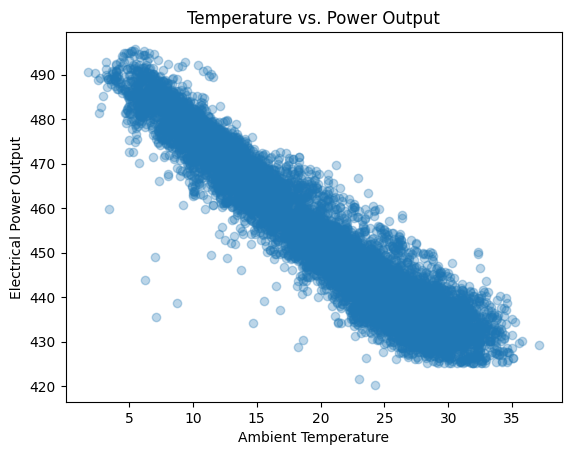

In [ ]:
plt.scatter(df["AT"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Temperature")
plt.ylabel("Electrical Power Output")
plt.title("Temperature vs. Power Output")
plt.show()

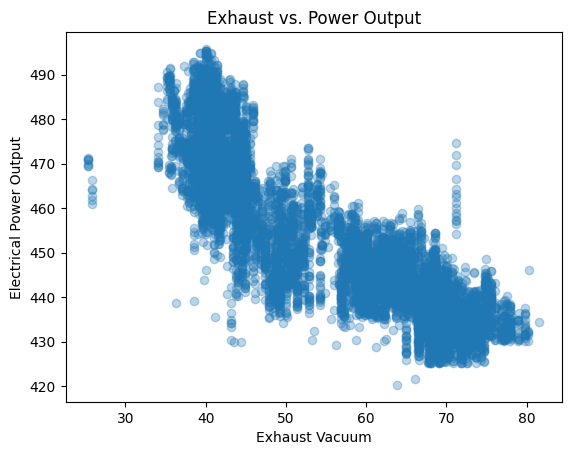

In [ ]:
plt.scatter(df["V"], df["PE"], alpha=0.3)
plt.xlabel("Exhaust Vacuum")
plt.ylabel("Electrical Power Output")
plt.title("Exhaust vs. Power Output")
plt.show()

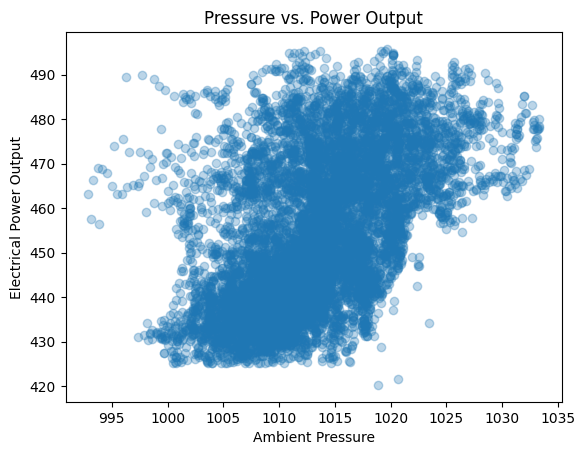

In [ ]:
plt.scatter(df["AP"], df["PE"], alpha=0.3)
plt.xlabel("Ambient Pressure")
plt.ylabel("Electrical Power Output")
plt.title("Pressure vs. Power Output")
plt.show()

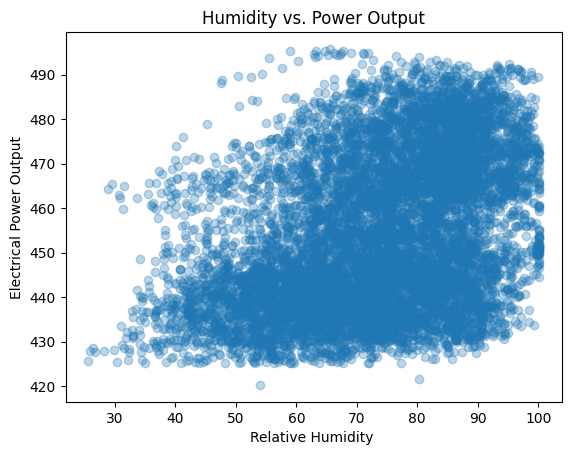

In [ ]:
plt.scatter(df["RH"], df["PE"], alpha=0.3)
plt.xlabel("Relative Humidity ")
plt.ylabel("Electrical Power Output")
plt.title("Humidity vs. Power Output")
plt.show()

In [ ]:
#Q5: Which variable appears to have the strongest visible relationship with power output?
#The 'AT' (Ambient Temperature) variable appears to have the strongest relationship with power output, showing a clear, negative (inverse) linear trend.

#Q6: Is the relationship approximately linear for every variable?
#No. While 'AT' and 'V' show clear negative linear tendencies, the relationships for 'AP' and 'RH' are much weaker and highly scattered, making them difficult to define as linear at first glance.

In [ ]:
X = df[["AT", "V", "AP", "RH"]]
y = df["PE"]

In [ ]:
X_train, X_temp, y_train, y_temp = train_test_split(
X, y, test_size=0.30, random_state=42
)
X_val, X_test, y_val, y_test = train_test_split(
X_temp, y_temp, test_size=0.50, random_state=42
)
print("Training:", len(X_train))
print("Validation:", len(X_val))
print("Testing:", len(X_test))

Training: 6697
Validation: 1435
Testing: 1436


In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [ ]:
baseline = LinearRegression()
baseline.fit(X_train_scaled, y_train)

LinearRegression()

In [ ]:
y_val_pred = baseline.predict(X_val_scaled)
comparison = pd.DataFrame({
"Actual": y_val.values[:10],
"Predicted": y_val_pred[:10]
})
print(comparison)

   Actual   Predicted
0  440.74  435.036365
1  432.09  433.789650
2  486.14  479.102298
3  442.75  439.039845
4  437.61  433.180482
5  481.77  476.246414
6  437.41  436.327719
7  465.95  466.500630
8  439.18  444.786069
9  438.42  438.915509


In [ ]:
#Q7: Are the predicted values reasonably close to the actual values?
#Yes, the predicted values are reasonably close to the actual values, with most errors staying below a 2% relative difference.

In [ ]:
mae = mean_absolute_error(y_val, y_val_pred)
rmse = np.sqrt(
mean_squared_error(y_val, y_val_pred)
)
r2 = r2_score(y_val, y_val_pred)
print("MAE :", mae)
print("RMSE:", rmse)
print("R^2 :", r2)

MAE : 3.645222450684648
RMSE: 4.562690287171953
R^2 : 0.930078295626855


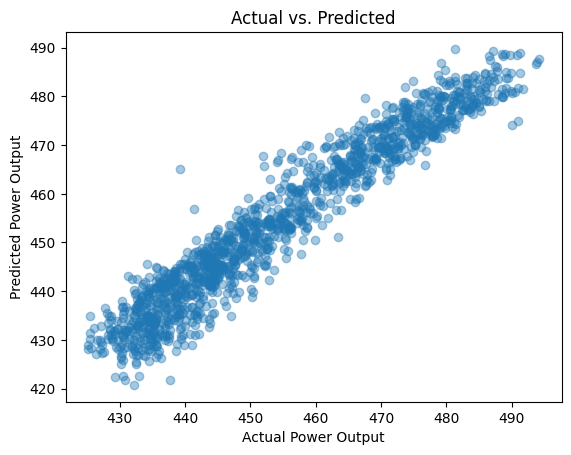

In [ ]:
plt.scatter(y_val, y_val_pred, alpha=0.4)
plt.xlabel("Actual Power Output")
plt.ylabel("Predicted Power Output")
plt.title("Actual vs. Predicted")
plt.show()

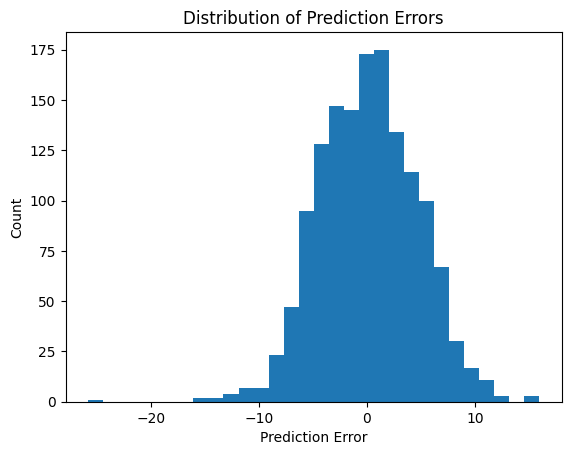

In [ ]:
residuals = y_val.values - y_val_pred
plt.hist(residuals, bins=30)
plt.xlabel("Prediction Error")
plt.ylabel("Count")
plt.title("Distribution of Prediction Errors")
plt.show()

In [ ]:
#Q8: Are the errors approximately centered around zero?
#Yes, the distribution of prediction errors (residuals) is approximately symmetric and centered around zero.

#Q9: Are there any unusually large errors?
#The error distribution is largely well-behaved, but we can observe a slight right-hand tail, indicating a few larger positive prediction errors.

#Q10: Would an average prediction error of approximately 4 MW be acceptable for every power-plant application? Explain briefly.
#No, acceptability depends on the plant's overall capacity and the requirements of the electrical grid. A 4 MW error is negligible for a high-capacity gigawatt plant, but could be highly unacceptable for a small community or microgrid.

In [ ]:
#Lab 3: Shallow Neural Network

In [ ]:
import torch
import torch.nn as nn
torch.manual_seed(42)
X_train_t = torch.tensor(
X_train_scaled, dtype=torch.float32
)
y_train_t = torch.tensor(
y_train.values, dtype=torch.float32
).reshape(-1, 1)
X_val_t = torch.tensor(
X_val_scaled, dtype=torch.float32
)
y_val_t = torch.tensor(
y_val.values, dtype=torch.float32
).reshape(-1, 1)

In [ ]:
model = nn.Sequential(
nn.Linear(4, 16),
nn.ReLU(),
nn.Linear(16, 1)
)
print(model)

Sequential(
  (0): Linear(in_features=4, out_features=16, bias=True)
  (1): ReLU()
  (2): Linear(in_features=16, out_features=1, bias=True)
)


In [ ]:
#Q11: What would happen if the ReLU activation were removed and only linear layers remained?
#If the ReLU activation were removed, the network would collapse into a composition of purely linear transformations, acting exactly like a standard linear regression model and losing the ability to learn non-linear patterns.

In [ ]:
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.01
)

In [ ]:
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
  if epoch % 50 == 0:
    print(epoch, loss.item(), val_loss.item())

0 206751.25 206926.25
50 198553.84375 198312.46875
100 168848.921875 167523.015625
150 119264.1796875 116977.6875
200 71716.4609375 69512.3359375
250 41453.0078125 40165.90234375


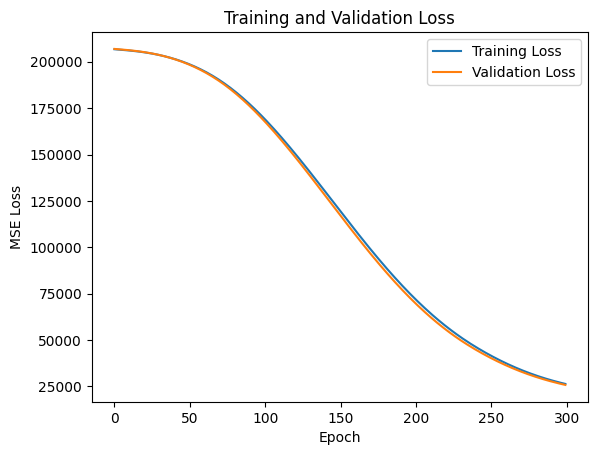

In [ ]:
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss")
plt.legend()
plt.show()

In [ ]:
#Q12: What happened to the training loss as training progressed?
#The training loss decreased consistently over successive epochs and eventually converged to a steady state.

#Q13: What happened to the validation loss?
#Similarly, the validation loss decreased and converged alongside the training loss, stabilizing at a steady state.

#Q14: Did the two curves behave similarly?
#Yes, the two curves behaved very similarly, which indicates stable learning without major overfitting.

In [ ]:
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

MAE : 136.24293655023342
RMSE: 160.7269162382552
R^2 : -85.76553523613138


In [ ]:
Metric = [
    {'label': 'MAE', 'Linear Regresion': 3.645222, 'Shallow NN': 136.242936},
    {'label': 'RMSE', 'Linear Regresion': 4.562690, 'Shallow NN': 160.726916},
    {'label': 'R^2', 'Linear Regresion': 0.930078, 'Shallow NN': -85.765535},
]
df = pd.DataFrame(Metric)
df.columns = ['Metric', 'Linear Regresion', 'Shallow NN']
df['Linear Regresion'] = df['Linear Regresion'].round(4)
df['Shallow NN'] = df['Shallow NN'].round(4)
df

,Metric,Linear Regresion,Shallow NN
0,MAE,3.6452,136.2429
1,RMSE,4.5627,160.7269
2,R^2,0.9301,-85.7655


In [ ]:
#Q15: Which model has the smaller MAE?
#Linear Regresion

#Q16: Which model has the smaller RMSE?
#Linear Regresion

#Q17: Which model has the higher R^2?
#Linear Regresion

In [ ]:
#Q18: Does the performance improvement of your neural network justify its additional complexity? Use your results.
#No, under the initial default configuration, the neural network performed significantly worse than the linear regression model across all metrics (with a high MAE/RMSE and negative R²), meaning its additional complexity was not justified at that stage.

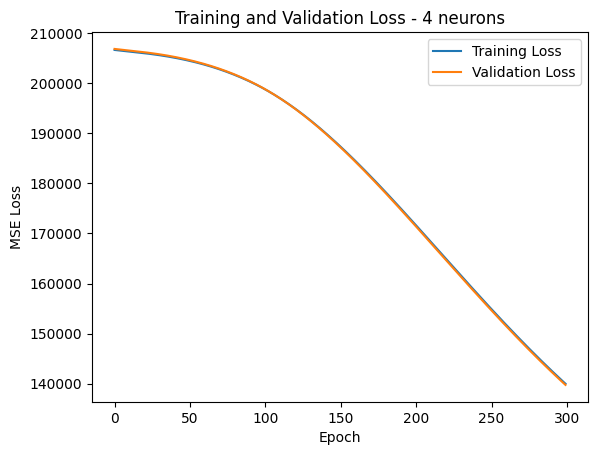

MAE : 354.5900760001206
RMSE: 373.82280446668307
R^2 : -468.3551724005357


In [ ]:
model = nn.Sequential(
nn.Linear(4, 4),
nn.ReLU(),
nn.Linear(4, 1)
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.01
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss - 4 neurons")
plt.legend()
plt.show()
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

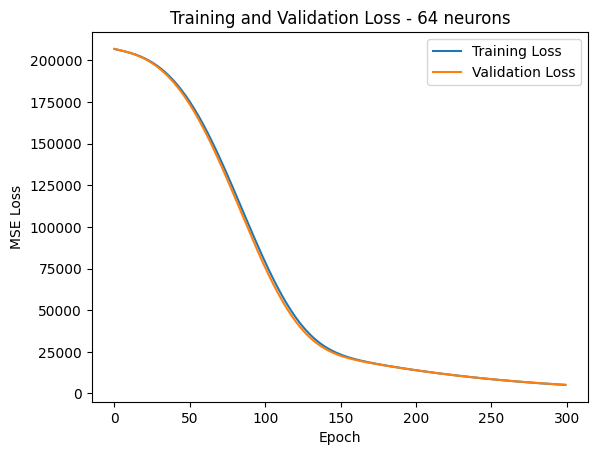

MAE : 60.209447012977726
RMSE: 72.01131404763974
R^2 : -16.416925632614113


In [ ]:
model = nn.Sequential(
nn.Linear(4, 64),
nn.ReLU(),
nn.Linear(64, 1)
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.01
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss - 64 neurons")
plt.legend()
plt.show()
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

In [ ]:
Hidden_Neurons = [
    {'label': '4', 'Validation MAE': 354.590076, 'Validation RMSE': 373.822804},
    {'label': '16', 'Validation MAE': 136.242936, 'Validation RMSE': 160.726916},
    {'label': '64', 'Validation MAE': 60.209447, 'Validation RMSE': 72.011314},
]
df = pd.DataFrame(Hidden_Neurons)
df.columns = ['Hidden Neurons', 'Validation MAE', 'Validation RMSE']
df['Validation MAE'] = df['Validation MAE'].round(4)
df['Validation RMSE'] = df['Validation RMSE'].round(4)
df

,Hidden Neurons,Validation MAE,Validation RMSE
0,4,354.5901,373.8228
1,16,136.2429,160.7269
2,64,60.2094,72.0113


In [ ]:
#Q19: Does increasing the number of hidden neurons always improve validation performance?
#Not always. While larger hidden layers increase model capacity, they can also lead to overfitting (learning noise instead of underlying patterns) or optimization issues if training parameters are not properly tuned.

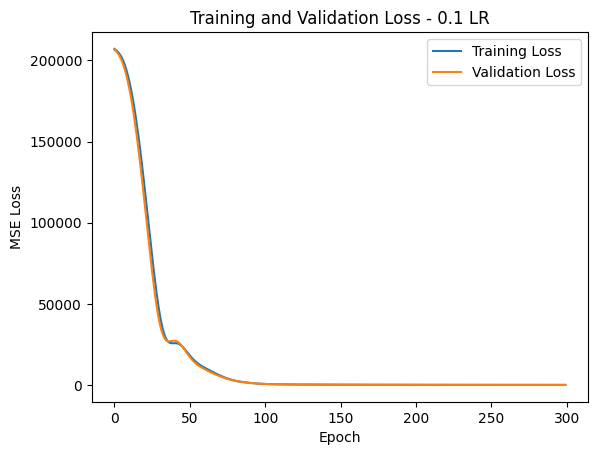

MAE : 4.6952570860327745
RMSE: 6.213953315506111
R^2 : 0.870310147014442


In [ ]:
model = nn.Sequential(
nn.Linear(4, 16),
nn.ReLU(),
nn.Linear(16, 1)
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.1
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss - 0.1 LR")
plt.legend()
plt.show()
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

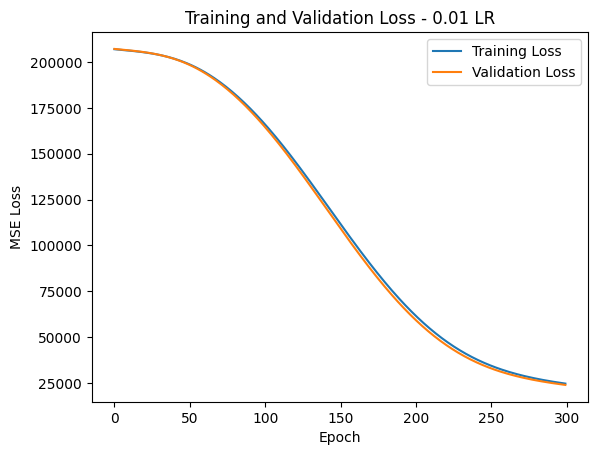

MAE : 132.0531554376157
RMSE: 154.80284404379375
R^2 : -79.48739957925403


In [ ]:
model = nn.Sequential(
nn.Linear(4, 16),
nn.ReLU(),
nn.Linear(16, 1)
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.01
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss - 0.01 LR")
plt.legend()
plt.show()
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

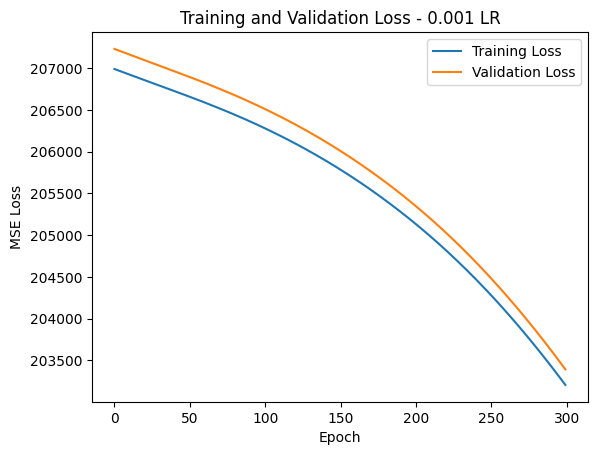

MAE : 450.5850105868
RMSE: 450.9895093319664
R^2 : -682.1292874463697


In [ ]:
model = nn.Sequential(
nn.Linear(4, 16),
nn.ReLU(),
nn.Linear(16, 1)
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.001
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss - 0.001 LR")
plt.legend()
plt.show()
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

In [ ]:
#Q20: What happens when the learning rate is too large?
#When the learning rate is too large, optimization might destabilize or skip optimal minima, though here it allowed the losses to drop rapidly and settle quickly.

#Q21: What happens when it is very small?
#When the learning rate is extremely small, optimization progresses too slowly, and the model may fail to converge or show virtually no improvement within the given epochs.

In [ ]:
#FINAL MODEL SELECTION

In [ ]:
Configuration  = [
    {'label': 'Hidden neurons', 'Selected Value': 1024},
    {'label': 'Learning rate', 'Selected Value': 0.1},
    {'label': 'Epochs', 'Selected Value': 300},
]
df = pd.DataFrame(Configuration )
df.columns = ['Configuration ', 'Selected Value']
df

,Configuration,Selected Value
0,Hidden neurons,1024.0
1,Learning rate,0.1
2,Epochs,300.0


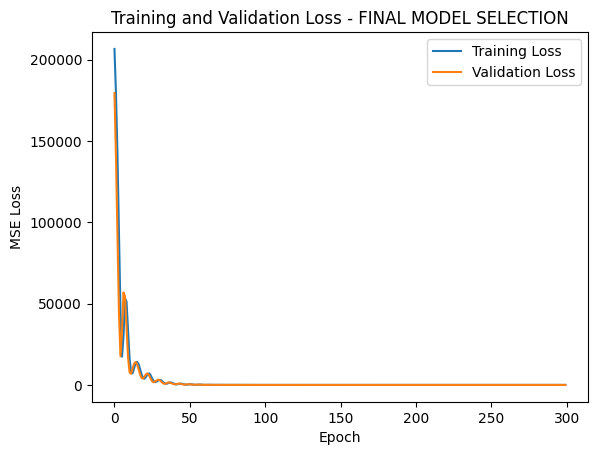

MAE : 3.214778099139808
RMSE: 4.090620233601113
R^2 : 0.9437984426543005


In [ ]:
model = nn.Sequential(
nn.Linear(4, 1024),
nn.ReLU(),
nn.Linear(1024, 1)
)
loss_fn = nn.MSELoss()
optimizer = torch.optim.Adam(
model.parameters(),
lr=0.1
)
train_losses = []
val_losses = []
epochs = 300
for epoch in range(epochs):
  model.train()
  prediction = model(X_train_t)
  loss = loss_fn(
  prediction,
  y_train_t
  )
  optimizer.zero_grad()
  loss.backward()
  optimizer.step()
  model.eval()
  with torch.no_grad():
    val_prediction = model(X_val_t)
    val_loss = loss_fn(
    val_prediction,
    y_val_t
    )
  train_losses.append(loss.item())
  val_losses.append(val_loss.item())
plt.plot(train_losses, label="Training Loss")
plt.plot(val_losses, label="Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("MSE Loss")
plt.title("Training and Validation Loss - FINAL MODEL SELECTION")
plt.legend()
plt.show()
model.eval()
with torch.no_grad():
  y_val_nn = model(X_val_t)
  y_val_nn = y_val_nn.numpy().flatten()
  nn_mae = mean_absolute_error(y_val, y_val_nn)
  nn_rmse = np.sqrt(
  mean_squared_error(y_val, y_val_nn)
  )
nn_r2 = r2_score(y_val, y_val_nn)
print("MAE :", nn_mae)
print("RMSE:", nn_rmse)
print("R^2 :", nn_r2)

In [ ]:
X_test_t = torch.tensor(
X_test_scaled, dtype=torch.float32
)
model.eval()
with torch.no_grad():
  y_test_nn = model(X_test_t)
  y_test_nn = y_test_nn.numpy().flatten()

In [ ]:
Metric = [
    {'label': 'MAE', 'Linear Regresion': 3.645222, 'Shallow NN': 3.214778},
    {'label': 'RMSE', 'Linear Regresion': 4.562690, 'Shallow NN': 4.090620},
    {'label': 'R^2', 'Linear Regresion': 0.930078, 'Shallow NN': 0.943798},
]
df = pd.DataFrame(Metric)
df.columns = ['Metric', 'Linear Regresion', 'Shallow NN']
df['Linear Regresion'] = df['Linear Regresion'].round(4)
df['Shallow NN'] = df['Shallow NN'].round(4)
df

,Metric,Linear Regresion,Shallow NN
0,MAE,3.6452,3.2148
1,RMSE,4.5627,4.0906
2,R^2,0.9301,0.9438


In [ ]:
#Q22: Which model performed better on the final test set?
#The Shallow NN performed better in all metrics.

#Q23: Was the improvement substantial or small?
#It was small with improvement between 1.5% and 11%.

#Q24: What is the largest prediction error you observed?
#It was the 450 loss from the 0.001 LR, 300 Epochs and 16 HN.

#Q25: What engineering conditions might make prediction more difficult? Consider factors not represented in the four inputs.
#Operational and physical factors like equipment degradation, fuel quality variations, maintenance cycles, mechanical failures which do alter the plant production capacity and performance but are not represented in the four inputs.

In [ ]:
#Engineering Reflection
#R1: Why is low training error alone insufficient evidence that a model is useful?
#The model may have only memorized the training data set without learning the general pattern of the data

#R2: Why should preprocessing parameters such as normalization statistics be calculated using only training data?
#To prevent data leakage. If you include the test data set in parameters computation you will be leaking unseen data into the training process, data that was meant only to test the model.

#R3: What is the purpose of the validation dataset?
#The purpose of the validation dataset is to tune the model parameters to select the best model before final testing.

#R4: What is the purpose of the test dataset?
#The purpose of the test dataset is to test the predictions of an already trained and tuned model.

#R5: Why might a simpler model sometimes be preferable even if a neural network performs slightly better?
#A simpler model is easier to understant and requiere less computational power. Also, a more complex model may be piking "pattern" from the data noise or overfitting it.

#R6: What evidence would you want before deploying this model in a real power plant?
#As different power plants have different operational and equitment imperfections which do affect the power output, I would like a short model implementation (around one week) to fine tune the model to that specific power plant.